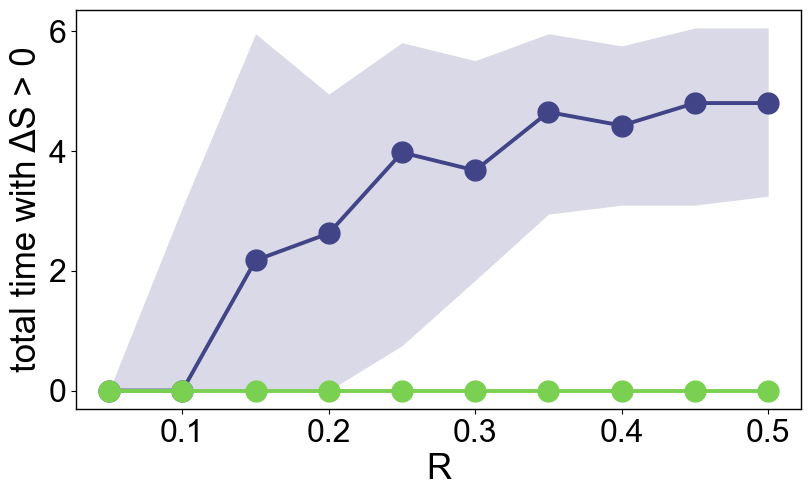

Saved: figs_entropy/timepos_entropy_positive_median_quantiles.pdf


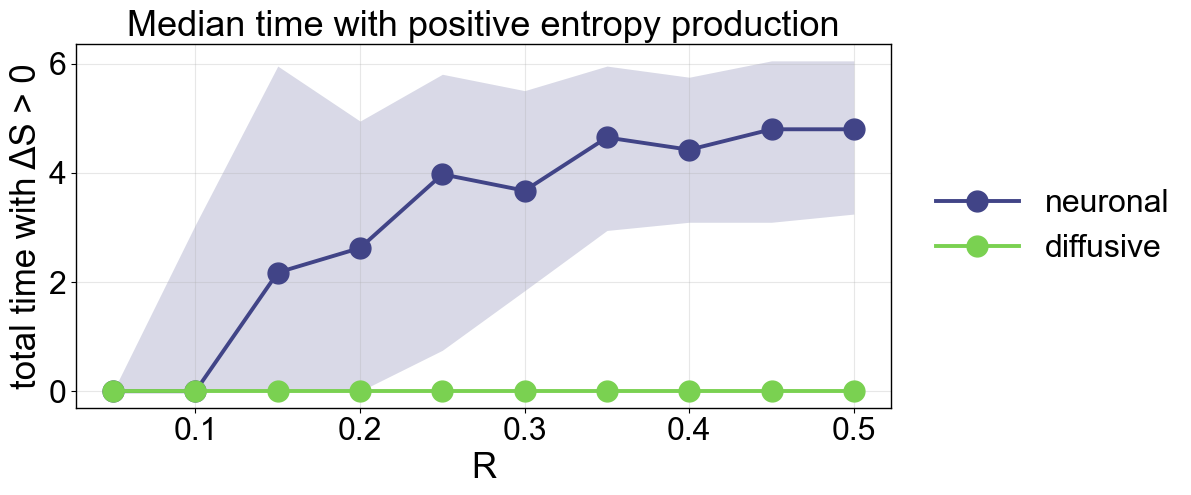

Saved: figs_entropy/timepos_entropy_positive_median_quantiles_WITH_legend_and_title2.pdf


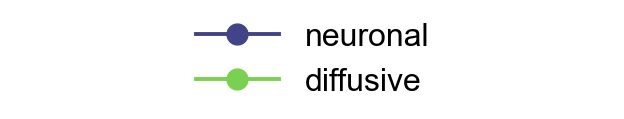

Saved: figs_entropy/legend_timepos_entropy_positive_median_quantiles2.pdf


In [1]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# ============================================================
# Style (same as your previous figures)
# ============================================================
FONT_SIZE = 25

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": FONT_SIZE,

    "axes.titlesize": FONT_SIZE + 1,
    "axes.labelsize": FONT_SIZE,
    "axes.linewidth": 1.0,

    "xtick.labelsize": FONT_SIZE - 2,
    "ytick.labelsize": FONT_SIZE - 2,

    "legend.fontsize": FONT_SIZE - 2,
    "legend.frameon": False,

    # math (avoid ⟨ ⟩ issues)
    "mathtext.fontset": "dejavuserif",
    "mathtext.rm": "DejaVu Serif",
    "mathtext.it": "DejaVu Serif:italic",
    "mathtext.bf": "DejaVu Serif:bold",

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ============================================================
# Inputs
# ============================================================
files = [
    "entropy_neuronal_vs_diffusive_ensemble.npz",
    "entropy_neuronal_vs_diffusive_ensemble1.npz",
]

OUTDIR = "figs_entropy"
os.makedirs(OUTDIR, exist_ok=True)

# ============================================================
# Helpers
# ============================================================
def total_positive_time(S, dt_eff, tol=1e-10):
    """Total time with ΔS > tol for one realization."""
    S = np.asarray(S)

    mask = np.isfinite(S[:-1]) & np.isfinite(S[1:])
    dS = S[1:] - S[:-1]

    return float(np.sum((dS > tol) & mask) * dt_eff)


def quantile_timepos(S_block, dt_eff, q_low=0.16, q_high=0.84):
    """
    S_block: (z, n_samp) for a fixed R
    Returns: median, q_low, q_high across realizations
    (uses only fully finite trajectories).
    """
    vals = []
    for i in range(S_block.shape[0]):
        Si = S_block[i]
        if np.all(np.isfinite(Si)):
            vals.append(total_positive_time(Si, dt_eff))

    if len(vals) == 0:
        return np.nan, np.nan, np.nan

    vals = np.asarray(vals)
    med = np.quantile(vals, 0.50)
    ql  = np.quantile(vals, q_low)
    qh  = np.quantile(vals, q_high)
    return float(med), float(ql), float(qh)


def extract_run_quantiles(npz_path, q_low=0.16, q_high=0.84):
    """
    Extract quantiles for BOTH neuronal and diffusive cases.
    Returns:
      R_grid,
      neur_med, neur_qlo, neur_qhi,
      diff_med, diff_qlo, diff_qhi
    """
    d = np.load(npz_path, allow_pickle=True)

    R_grid = np.array(d["R_grid"], dtype=float)
    dt_eff = float(d["dt_eff"])
    S_neur = d["S_neur"]   # (n_R, z, n_samp)
    S_diff = d["S_diff"]  # (n_R, z, n_samp)

    n_R = S_neur.shape[0]

    neur_med = np.full(n_R, np.nan)
    neur_qlo = np.full(n_R, np.nan)
    neur_qhi = np.full(n_R, np.nan)

    diff_med = np.full(n_R, np.nan)
    diff_qlo = np.full(n_R, np.nan)
    diff_qhi = np.full(n_R, np.nan)

    for r in range(n_R):
        neur_med[r], neur_qlo[r], neur_qhi[r] = quantile_timepos(
            S_neur[r], dt_eff, q_low, q_high
        )
        diff_med[r], diff_qlo[r], diff_qhi[r] = quantile_timepos(
            S_diff[r], dt_eff, q_low, q_high
        )

    return (
        R_grid,
        neur_med, neur_qlo, neur_qhi,
        diff_med, diff_qlo, diff_qhi
    )

# ============================================================
# Load + merge the two runs (no overlap in R)
# ============================================================
R_all = []
nm_med = []; nm_lo = []; nm_hi = []
dm_med = []; dm_lo = []; dm_hi = []

for f in files:
    R, nmed, nlo, nhi, dmed, dlo, dhi = extract_run_quantiles(f)
    R_all.append(R)
    nm_med.append(nmed); nm_lo.append(nlo); nm_hi.append(nhi)
    dm_med.append(dmed); dm_lo.append(dlo); dm_hi.append(dhi)

R_all  = np.concatenate(R_all)
nm_med = np.concatenate(nm_med)
nm_lo  = np.concatenate(nm_lo)
nm_hi  = np.concatenate(nm_hi)
dm_med = np.concatenate(dm_med)
dm_lo  = np.concatenate(dm_lo)
dm_hi  = np.concatenate(dm_hi)

# sort by R
idx = np.argsort(R_all)
R_all, nm_med, nm_lo, nm_hi, dm_med, dm_lo, dm_hi = (
    R_all[idx],
    nm_med[idx], nm_lo[idx], nm_hi[idx],
    dm_med[idx], dm_lo[idx], dm_hi[idx],
)

# ============================================================
# Colors
# ============================================================
cmap = plt.get_cmap("viridis")
c_neur = cmap(0.20)
c_diff = cmap(0.80)

# ============================================================
# Plot: MEDIAN + 16–84% QUANTILES (NO LEGEND)
# ============================================================
fig, ax = plt.subplots(figsize=(220 / 25.4, 140 / 25.4 ))

ax.plot(R_all, nm_med, "-o", lw=2.8, markersize=15, color=c_neur)
ax.fill_between(R_all, nm_lo, nm_hi, color=c_neur, alpha=0.20, linewidth=0)

ax.plot(R_all, dm_med, "-o", lw=2.8, markersize=15, color=c_diff)
ax.fill_between(R_all, dm_lo, dm_hi, color=c_diff, alpha=0.20, linewidth=0)

ax.set_xlabel("R")
ax.set_ylabel("total time with ΔS > 0")
ax.grid(False)

fig.tight_layout()
pdf_main = os.path.join(OUTDIR, "timepos_entropy_positive_median_quantiles.pdf")
fig.savefig(pdf_main, bbox_inches="tight")
plt.show()
print("Saved:", pdf_main)

# ============================================================
# Plot: SAME FIGURE + LEGEND INCLUDED + TITLE (LEGEND OUTSIDE)
# ============================================================
fig2, ax2 = plt.subplots(figsize=(12.5, 5.5))

ax2.plot(R_all, nm_med, "-o", lw=2.8, markersize=15,
         color=c_neur, label="neuronal")
ax2.fill_between(R_all, nm_lo, nm_hi, color=c_neur, alpha=0.20, linewidth=0)

ax2.plot(R_all, dm_med, "-o", lw=2.8, markersize=15,
         color=c_diff, label="diffusive")
ax2.fill_between(R_all, dm_lo, dm_hi, color=c_diff, alpha=0.20, linewidth=0)

ax2.set_xlabel("R")
ax2.set_ylabel("total time with ΔS > 0")
ax2.grid(True, alpha=0.3)


ax2.set_title("Median time with positive entropy production")


ax2.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncol=1,
    handlelength=2.6,
    columnspacing=2.5,
    frameon=False
)

fig2.tight_layout()
pdf_main_with_leg = os.path.join(
    OUTDIR, "timepos_entropy_positive_median_quantiles_WITH_legend_and_title2.pdf"
)
fig2.savefig(pdf_main_with_leg, bbox_inches="tight")
plt.show()
print("Saved:", pdf_main_with_leg)

# ============================================================
# Standalone legend (separate PDF)
# ============================================================
figL, axL = plt.subplots(figsize=(6.8, 1.4))
axL.axis("off")

axL.plot([], [], "-o", lw=2.8, markersize=15, color=c_neur, label="neuronal")
axL.plot([], [], "-o", lw=2.8, markersize=15, color=c_diff, label="diffusive")

axL.legend(
    loc="center",
    ncol=1,
    handlelength=2.6,
    columnspacing=2.5,
    frameon=False
)

figL.tight_layout()
pdf_leg = os.path.join(OUTDIR, "legend_timepos_entropy_positive_median_quantiles2.pdf")
figL.savefig(pdf_leg, bbox_inches="tight")
plt.show()
print("Saved:", pdf_leg)
